# PH1050 Project 8 — Radar and Sonar Echoes
**Data collection notebook (Google Colab ready)**

**Project question:** Can we distinguish a metal cylinder from a rock using the echo it sends back?

This notebook does four things:
1. Downloads the **real UCI Sonar** labelled dataset (208 returns, 60 frequency-band energy features).
2. Checks and exports the raw/clean dataset so teammates can analyse it.
3. Creates a separate **synthetic echo dataset** with 200 examples per class (clearly labelled as simulated), useful for testing noise sensitivity and the physics model.
4. Creates a simple noisy echo-time example and exports the data.



## 1. Install/import packages

In [ ]:
# Install the package used to download the UCI dataset
!pip -q install ucimlrepo

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ucimlrepo import fetch_ucirepo

# Keep the generated files together in one folder
np.random.seed(42)
os.makedirs("project8_data", exist_ok=True)


## 2. Download the real UCI Sonar dataset

In [ ]:
# Download the Sonar dataset from the UCI Machine Learning Repository
sonar = fetch_ucirepo(id=151)

features = sonar.data.features.copy()
labels = sonar.data.targets.copy()

# Rename the 60 columns so it is easier to identify each energy feature
features.columns = [f"energy_bin_{i:02d}" for i in range(1, features.shape[1] + 1)]

real_df = features.copy()
real_df["label"] = labels.iloc[:, 0].astype(str).str.strip().str.upper().values

# M represents a metal cylinder and R represents a rock
real_df["class_name"] = real_df["label"].map({
    "M": "metal_cylinder",
    "R": "rock"
})

print("Dataset size:", real_df.shape)
print("\nNumber of samples in each class:")
print(real_df["class_name"].value_counts())
display(real_df.head())


Shape: (208, 62)

Class counts:
class_name
metal_cylinder    111
rock               97
Name: count, dtype: int64


,energy_bin_01,energy_bin_02,energy_bin_03,energy_bin_04,energy_bin_05,energy_bin_06,energy_bin_07,energy_bin_08,energy_bin_09,energy_bin_10,...,energy_bin_53,energy_bin_54,energy_bin_55,energy_bin_56,energy_bin_57,energy_bin_58,energy_bin_59,energy_bin_60,label,class_name
0,0.0200,0.0371,0.0428,0.0207,0.0954,0.0986,0.1539,0.1601,0.3109,0.2111,...,0.0065,0.0159,0.0072,0.0167,0.0180,0.0084,0.0090,0.0032,R,rock
1,0.0453,0.0523,0.0843,0.0689,0.1183,0.2583,0.2156,0.3481,0.3337,0.2872,...,0.0089,0.0048,0.0094,0.0191,0.0140,0.0049,0.0052,0.0044,R,rock
2,0.0262,0.0582,0.1099,0.1083,0.0974,0.2280,0.2431,0.3771,0.5598,0.6194,...,0.0166,0.0095,0.0180,0.0244,0.0316,0.0164,0.0095,0.0078,R,rock
3,0.0100,0.0171,0.0623,0.0205,0.0205,0.0368,0.1098,0.1276,0.0598,0.1264,...,0.0036,0.0150,0.0085,0.0073,0.0050,0.0044,0.0040,0.0117,R,rock
4,0.0762,0.0666,0.0481,0.0394,0.0590,0.0649,0.1209,0.2467,0.3564,0.4459,...,0.0054,0.0105,0.0110,0.0015,0.0072,0.0048,0.0107,0.0094,R,rock


## 3. Data-quality checks and export

In [ ]:
# Select the 60 energy features
feature_cols = [col for col in real_df.columns if col.startswith("energy_bin_")]

# Check the dataset before cleaning it
print("Missing values:", int(real_df.isna().sum().sum()))
print("Duplicate rows:", int(real_df.duplicated().sum()))
print("Smallest feature value:", float(real_df[feature_cols].min().min()))
print("Largest feature value:", float(real_df[feature_cols].max().max()))

# Remove rows that are missing a feature value or class label
rows_before = len(real_df)
clean_real = real_df.dropna(subset=feature_cols + ["label"]).copy()
rows_after = len(clean_real)

print(f"Rows before cleaning: {rows_before}")
print(f"Rows after cleaning: {rows_after}")
print(f"Rows removed: {rows_before - rows_after}")

# Save the cleaned real dataset
clean_real.to_csv("project8_data/uci_sonar_clean.csv", index=False)
print("Cleaned dataset saved.")


Missing values: 0
Duplicate rows: 0
Feature minimum: 0.0
Feature maximum: 1.0
Rows before cleaning: 208; rows after cleaning: 208; removed: 0
Saved project8_data/uci_sonar_clean.csv


## 4. Plot average measured energy profiles

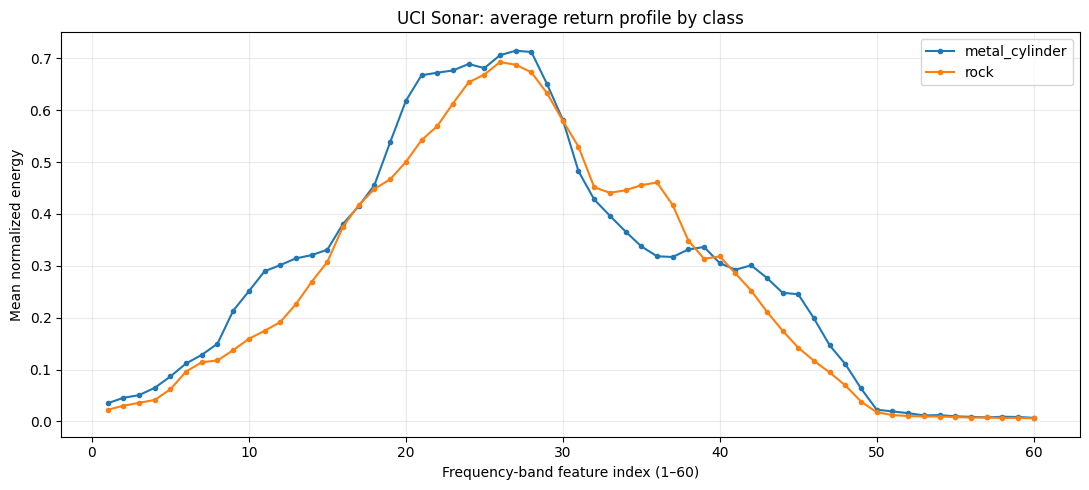

In [ ]:
# Compare the average energy profile for rocks and metal cylinders
mean_profile = clean_real.groupby("class_name")[feature_cols].mean().T

plt.figure(figsize=(11, 5))

for class_name in mean_profile.columns:
    plt.plot(
        np.arange(1, 61),
        mean_profile[class_name],
        marker=".",
        label=class_name
    )

plt.xlabel("Frequency-band feature index (1–60)")
plt.ylabel("Mean normalized energy")
plt.title("Average UCI Sonar energy profile for each class")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()

plt.savefig("project8_data/uci_average_profiles.png", dpi=160)
plt.show()


## 5. Generate the assignment's optional synthetic dataset

The project statement allows generated data: 200 returns per class, pulse-echo energy in 60 bins, class-dependent reflection amplitude, plus noise. The code below uses a simple envelope, random variation, additive noise, and a secondary echo-like component (a deliberately omitted effect in the simple model).

This is **simulated data**, not a replacement for the UCI measurements.

In [ ]:
# Create an illustrative dataset with 200 simulated returns for each class
rng = np.random.default_rng(8)
samples_per_class = 200
bin_index = np.arange(60)
synthetic_rows = []

# These amplitudes are only used to make the two simulated classes different.
# They are not measured material properties.
class_amplitude = {
    "metal_cylinder": 0.72,
    "rock": 0.38
}

for class_name, amplitude in class_amplitude.items():
    for sample in range(samples_per_class):
        center = rng.uniform(18, 42)
        width = rng.uniform(7, 13)

        # Main echo shape
        envelope = np.exp(-0.5 * ((bin_index - center) / width) ** 2)

        # Add a small variation across the energy bins
        ripple = 1 + 0.12 * np.sin(
            2 * np.pi * bin_index / rng.uniform(7, 14)
            + rng.uniform(0, 2 * np.pi)
        )

        # Add a weaker secondary echo to represent scattering or multipath effects
        secondary_center = center + rng.uniform(8, 17)
        secondary = 0.16 * np.exp(
            -0.5 * ((bin_index - secondary_center) / rng.uniform(2, 5)) ** 2
        )

        # Add random noise and keep all energy values between 0 and 1
        noise = rng.normal(0, 0.045, 60)
        energy = np.clip(amplitude * envelope * ripple + secondary + noise, 0, 1)

        sample_id = f"{class_name[0].upper()}_{sample + 1:03d}"
        synthetic_rows.append([sample_id, class_name, *energy])

synthetic_cols = (
    ["return_id", "class"]
    + [f"energy_bin_{i:02d}" for i in range(1, 61)]
)

synthetic_df = pd.DataFrame(synthetic_rows, columns=synthetic_cols)

# Save the simulated dataset separately from the real UCI data
synthetic_df.to_csv("project8_data/synthetic_echo_returns_400.csv", index=False)

print("Synthetic dataset size:", synthetic_df.shape)
print("\nSamples in each class:")
print(synthetic_df["class"].value_counts())
display(synthetic_df.head())


(400, 62)
class
metal_cylinder    200
rock              200
Name: count, dtype: int64


,return_id,class,energy_bin_01,energy_bin_02,energy_bin_03,energy_bin_04,energy_bin_05,energy_bin_06,energy_bin_07,energy_bin_08,...,energy_bin_51,energy_bin_52,energy_bin_53,energy_bin_54,energy_bin_55,energy_bin_56,energy_bin_57,energy_bin_58,energy_bin_59,energy_bin_60
0,M_001,metal_cylinder,0.043014,0.145409,0.174782,0.225394,0.227409,0.214225,0.270107,0.307689,...,0.174122,0.236676,0.134349,0.072565,0.063513,0.016282,0.092110,0.023469,0.113633,0.014213
1,M_002,metal_cylinder,0.013337,0.087672,0.000000,0.025160,0.072486,0.027331,0.000000,0.000000,...,0.287463,0.286378,0.229033,0.218177,0.149198,0.093255,0.106973,0.006614,0.076046,0.000000
2,M_003,metal_cylinder,0.084028,0.046715,0.019823,0.118232,0.101628,0.005647,0.067670,0.131130,...,0.110443,0.163197,0.159496,0.150588,0.150717,0.117620,0.018271,0.002837,0.006542,0.045242
3,M_004,metal_cylinder,0.175937,0.219137,0.303227,0.266971,0.400377,0.462164,0.352485,0.401504,...,0.054881,0.000000,0.026460,0.000000,0.000000,0.002915,0.062998,0.000000,0.010767,0.000000
4,M_005,metal_cylinder,0.032091,0.000000,0.014764,0.000000,0.000000,0.000000,0.049164,0.011155,...,0.438103,0.491817,0.448785,0.633203,0.433303,0.459456,0.326600,0.330701,0.265160,0.236560


## 6. Add a higher-noise version for the required robustness comparison

In [ ]:
# Make another copy of the simulated data with a higher noise level
syn_features = [col for col in synthetic_df.columns if col.startswith("energy_bin_")]

high_noise_df = synthetic_df.copy()
noise_rng = np.random.default_rng(2026)

extra_noise = noise_rng.normal(
    0,
    0.10,
    size=(len(high_noise_df), len(syn_features))
)

high_noise_df[syn_features] = np.clip(
    high_noise_df[syn_features].to_numpy() + extra_noise,
    0,
    1
)

high_noise_df.to_csv(
    "project8_data/synthetic_echo_returns_high_noise.csv",
    index=False
)

print("Both simulated datasets have been saved.")


Saved low-noise and high-noise simulated datasets.


## 7. Physics dataset: echo timing and distance recovery

For sonar in water, the round-trip time is `t = 2d/v`, so `d = vt/2`. Here we create a **synthetic** pulse with a known target distance and sample it at different time intervals. The recovered peak gives an estimated distance. This supports the timing/convergence analysis in Part 1.

The assignment specifies `v = 1500 m/s` in water. The UCI Sonar table contains frequency-band energies, not raw timestamps, so do not claim the UCI rows directly provide echo travel times.

dt=2.00e-05 s | estimated d=119.970 m | abs error=0.030 m
dt=4.00e-05 s | estimated d=120.030 m | abs error=0.030 m
dt=8.00e-05 s | estimated d=120.000 m | abs error=0.000 m
dt=1.60e-04 s | estimated d=120.000 m | abs error=0.000 m
dt=3.20e-04 s | estimated d=120.000 m | abs error=0.000 m
dt=6.40e-04 s | estimated d=120.000 m | abs error=0.000 m


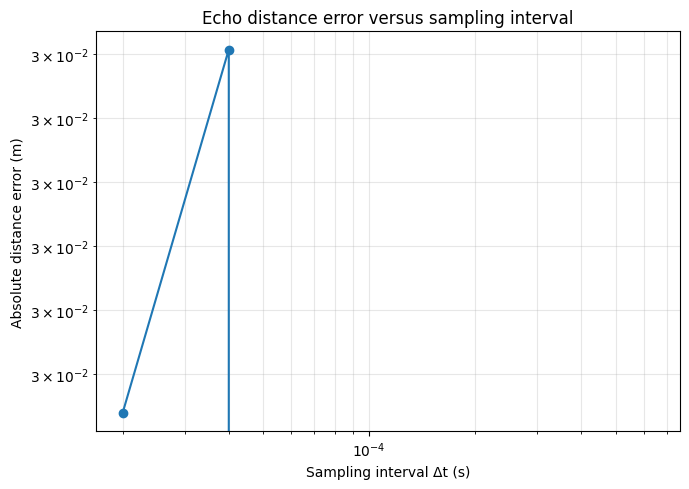

In [ ]:
# Example values for the sonar distance calculation
v_sound = 1500.0       # Speed of sound in water (m/s)
distance_true = 120.0  # Chosen target distance (m)

# The echo travels to the target and back, so the time is for a round trip
t_echo = 2 * distance_true / v_sound

pulse_width = 0.00020  # Example pulse width (s)
duration = 0.30        # Total time recorded (s)


def simulate_echo(dt, noise_std=0.025, seed=0):
    """Create a noisy echo signal and estimate the target distance."""
    rng = np.random.default_rng(seed)
    time = np.arange(0, duration, dt)

    # A Gaussian-shaped pulse represents the returning echo
    clean_signal = np.exp(-0.5 * ((time - t_echo) / pulse_width) ** 2)
    noisy_signal = clean_signal + rng.normal(0, noise_std, len(time))

    # Estimate the echo time from the largest signal value
    peak_time = time[np.argmax(noisy_signal)]
    estimated_distance = v_sound * peak_time / 2

    return time, noisy_signal, estimated_distance


# Check how the sampling interval affects the distance estimate
time_steps = np.array([2e-5, 4e-5, 8e-5, 1.6e-4, 3.2e-4, 6.4e-4])
errors = []

for i, dt in enumerate(time_steps):
    time, signal, estimated_distance = simulate_echo(dt, seed=100 + i)
    error = abs(estimated_distance - distance_true)
    errors.append(error)

    print(
        f"dt = {dt:.2e} s | "
        f"estimated distance = {estimated_distance:.3f} m | "
        f"error = {error:.3f} m"
    )

plt.figure(figsize=(7, 5))
plt.loglog(time_steps, errors, "o-")
plt.xlabel("Sampling interval Δt (s)")
plt.ylabel("Absolute distance error (m)")
plt.title("Effect of sampling interval on distance error")
plt.grid(True, which="both", alpha=0.3)
plt.tight_layout()

plt.savefig("project8_data/distance_error_vs_dt.png", dpi=160)
plt.show()


## 8. Export a compact data dictionary and README

## 7A. Material properties and ideal reflection prediction

The project asks for typical density and longitudinal-wave speed for water, steel and granite. The values below are representative literature values, not universal constants. For solids, use the compressional/P-wave speed. We calculate impedance as Z = ρv, then the ideal normal-incidence energy reflection fraction from water into each material.

Water: ρ=1000 kg/m³, v=1500 m/s (project brief / representative freshwater value). Steel: ρ=7860 kg/m³, v=5950 m/s (acoustic property table). Granite: ρ=2600 kg/m³, v=6000 m/s (approximate value from a seismic material-property table). Cite the selected sources in the report and state that actual values vary with sample and conditions.


In [ ]:
# Calculate acoustic impedance and the ideal energy reflection/transmission
materials = pd.DataFrame({
    "material": ["water", "steel", "granite"],
    "density_kg_m3": [1000, 7860, 2600],
    "longitudinal_speed_m_s": [1500, 5950, 6000]
})

# Acoustic impedance is density multiplied by wave speed
materials["impedance_rayl"] = (
    materials["density_kg_m3"] * materials["longitudinal_speed_m_s"]
)

Z_water = materials.loc[
    materials["material"] == "water", "impedance_rayl"
].iloc[0]

# Calculate the energy reflection and transmission coefficients
materials["R_energy_from_water"] = (
    (materials["impedance_rayl"] - Z_water)
    / (materials["impedance_rayl"] + Z_water)
) ** 2

materials["T_energy_from_water"] = (
    4 * Z_water * materials["impedance_rayl"]
    / (materials["impedance_rayl"] + Z_water) ** 2
)

materials["R_plus_T"] = (
    materials["R_energy_from_water"] + materials["T_energy_from_water"]
)

display(materials)
materials.to_csv(
    "project8_data/material_impedance_reflection.csv",
    index=False
)

print(
    "Does reflection + transmission equal 1?",
    np.allclose(materials["R_plus_T"], 1.0)
)


,material,density_kg_m3,longitudinal_speed_m_s,impedance_rayl,R_energy_from_water,T_energy_from_water,R_plus_T
0,water,1000,1500,1500000,0.000000,1.000000,1.0
1,steel,7860,5950,46767000,0.879555,0.120445,1.0
2,granite,2600,6000,15600000,0.679902,0.320098,1.0


Check R + T ≈ 1 for each interface: True
